# Medical MNIST — Image Classification, and Why 99% Accuracy Means Nothing Here

Classification of 58,954 medical images (64x64) across 6 imaging modalities:
`AbdomenCT`, `BreastMRI`, `CXR`, `ChestCT`, `Hand`, `HeadCT`.

**The point of this notebook is not the score.** A small CNN reaches ~99.8% on this
dataset, and that number is close to meaningless on its own. The interesting work is
figuring out *why* it is so high, and whether it can be trusted. So this notebook is
organised as an investigation:

1. Look at the data before modelling anything.
2. Fit a **linear baseline** first, so the CNN has something to beat.
3. Train the CNN and compare.
4. Evaluate properly — held-out test set, confusion matrix, and a look at every error.
5. **Audit the dataset for leakage**, because CT and MRI images come from volumes,
   and neighbouring slices of the same patient are nearly identical.

### Summary of results

| Model | Input | Test accuracy | Errors (out of 8,844) |
|---|---|---|---|
| Logistic regression | 16x16 raw pixels (256 features) | 99.38% | 55 |
| Small CNN (2 conv blocks) | 64x64 RGB | 99.97% | 3 |

A linear model on 256 downsampled pixels is within six tenths of a point of the CNN.
That is the real finding: **the six modalities are visually disjoint, so the task is
close to trivial**, and a high accuracy here is not evidence that the model is good.
(The CNN is not useless — it removes 94% of the errors the baseline still makes — but
that is a very different claim from "99.97%".)

## 1. Setup

In [13]:
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

# A single seed for the whole notebook, so every run is reproducible, and 67 
SEED = 67
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

DATA_DIR = "./archive"
print(f"Device: {device}")

Device: mps


## 2. Exploring the dataset

Before writing a single line of model code, the questions worth answering are: how many
classes are there, are they balanced, do all images share the same size, and — most
importantly — **how visually different are the classes from each other?** That last
question determines how hard the problem actually is.

6 classes found: ['AbdomenCT', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT']

AbdomenCT    | 10,000 images | shape (64, 64) | dtype uint8
BreastMRI    |  8,954 images | shape (64, 64) | dtype uint8
CXR          | 10,000 images | shape (64, 64) | dtype uint8
ChestCT      | 10,000 images | shape (64, 64) | dtype uint8
Hand         | 10,000 images | shape (64, 64) | dtype uint8
HeadCT       | 10,000 images | shape (64, 64) | dtype uint8


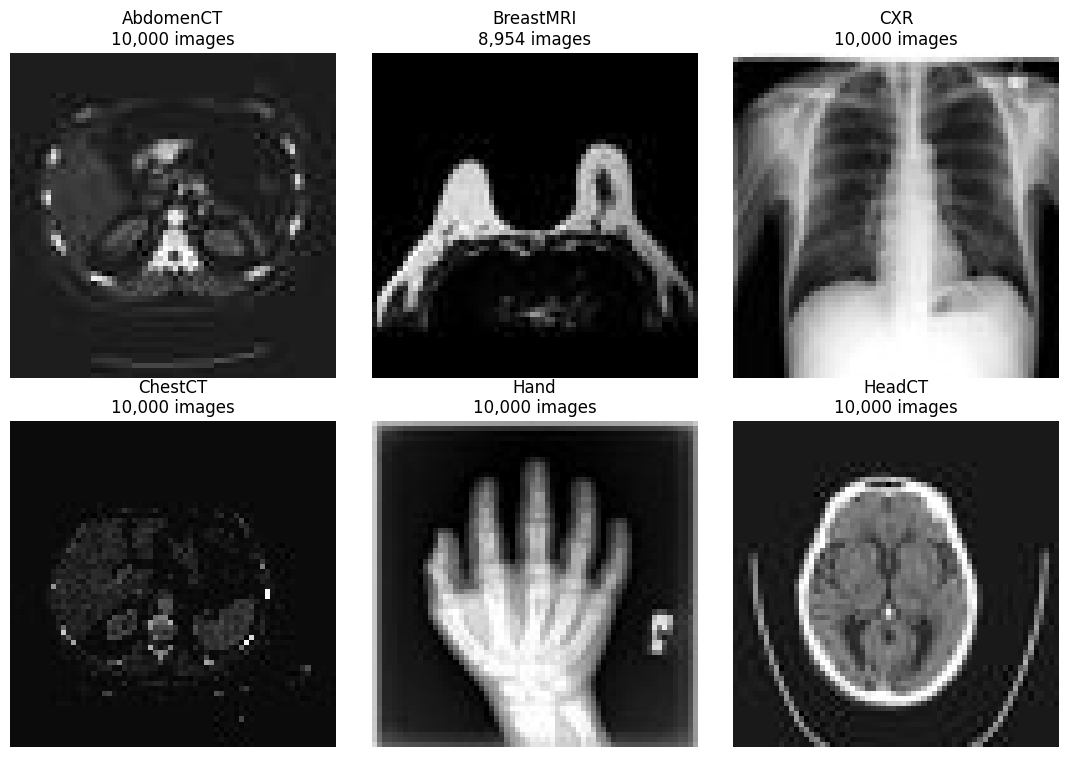


Total: 58,954 images
Class balance: min 8,954 / max 10,000


In [14]:
class_names = sorted(
    name
    for name in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, name))
)
print(f"{len(class_names)} classes found: {class_names}\n")

n_cols = 3
n_rows = math.ceil(len(class_names) / n_cols)
plt.figure(figsize=(11, 3.8 * n_rows))

counts = {}
for index, class_name in enumerate(class_names):
    class_dir = os.path.join(DATA_DIR, class_name)
    files = sorted(f for f in os.listdir(class_dir) if not f.startswith("."))
    counts[class_name] = len(files)

    image = plt.imread(os.path.join(class_dir, files[0]))
    print(f"{class_name:12s} | {len(files):6,d} images | shape {image.shape} | dtype {image.dtype}")

    plt.subplot(n_rows, n_cols, index + 1)
    plt.imshow(image, cmap="gray")
    plt.title(f"{class_name}\n{len(files):,} images")
    plt.axis("off")

plt.tight_layout()
plt.show()

print(f"\nTotal: {sum(counts.values()):,} images")
print(f"Class balance: min {min(counts.values()):,} / max {max(counts.values()):,}")

### What this tells us

Three observations, and one hypothesis.

**The dataset is clean and regular.** Every image is 64x64 and 8-bit greyscale, so no
resizing or format handling is needed. Classes are close to balanced — five classes have
exactly 10,000 images and `BreastMRI` has 8,954 — which means plain accuracy is a
reasonable metric and no class weighting is required.

**The classes are visually disjoint.** A chest X-ray, a hand radiograph and a breast MRI
do not resemble each other even slightly: they differ in silhouette, contrast, and the
overall distribution of bright pixels. So, our model will probably not need a lot of fine tunning.

**Prediction: the three CT classes should be the main source of confusion.**
`AbdomenCT`, `ChestCT` and `HeadCT` share the same imaging physics, so they share the
same texture and greyscale range. If the model makes mistakes, they sould be concentrate
there. A confusion matrix will help us to have a better understanding of our model and will help us to check if our predictions are correct.

Hypothesis to test: **this task is easy enough that a linear model will already solve
most of it.** That is exactly what the next section checks.

## 3. Preprocessing

In [15]:
# All images are already 64x64, but resizing explicitly makes the pipeline
# independent of the dataset and guarantees the CNN's input size
IMAGE_SIZE = 64

# ImageNet statistics. The images are greyscale but ImageFolder loads them as
# 3-channel RGB, so per-channel normalisation applies as usual.
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Augmentation is applied to the training set only
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

# Validation and test data are never augmented: we measure on clean images
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

### Reasoning behind these choices

**Two separate transform pipelines.** Augmentation belongs to training only. Applying a
random rotation to validation images would make the reported score depend on a random
draw, and would measure the model on inputs that no longer represent the deployment
distribution.

**Rotation and horizontal flip are safe here, but that is not automatic.** Flipping a
chest X-ray horizontally produces a mirrored anatomy — a heart on the wrong side. For
*modality* classification that is harmless, because we are asking "is this a CT or an
MRI", and the answer does not depend on left/right orientation. For a diagnostic task
(detecting dextrocardia, or lateralising a lesion) this augmentation would be actively
harmful. The choice is defensible because of what we are predicting, not because it is
a common default.

**ImageNet statistics for greyscale images** is a mild inconsistency: the three channels
are identical, so the three different means and standard deviations shift them apart
slightly. It is harmless — the first convolution can undo any affine per-channel
transformation — and it keeps the pipeline compatible with pretrained backbones if we
later swap in a ResNet.

## 4. Splitting the data: train / validation / test

As usual, we split our data in training, validation and test sets.

- **70% train** — gradient updates,
- **15% validation** — monitored during training, used for any tuning decision,
- **15% test** — touched exactly once, at the end, for the numbers reported.

The two `ImageFolder` objects below point at the same files; they differ only in the
transform applied. The split is done over *indices*, once, so that a given image lands
in exactly one of the three subsets.

In [16]:
dataset_augmented = datasets.ImageFolder(root=DATA_DIR, transform=train_transform)
dataset_plain = datasets.ImageFolder(root=DATA_DIR, transform=eval_transform)

n_total = len(dataset_augmented)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val

# One single draw produces all three index lists, which guarantees they are disjoint
generator = torch.Generator().manual_seed(SEED)
split_train, split_val, split_test = random_split(
    range(n_total), [n_train, n_val, n_test], generator=generator
)
train_idx, val_idx, test_idx = list(split_train), list(split_val), list(split_test)

# Same underlying images, different transforms depending on the subset
train_dataset = Subset(dataset_augmented, train_idx)
val_dataset = Subset(dataset_plain, val_idx)
test_dataset = Subset(dataset_plain, test_idx)

BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

assert not (set(train_idx) & set(val_idx)), "Overlap between train and validation"
assert not (set(train_idx) & set(test_idx)), "Overlap between train and test"
assert not (set(val_idx) & set(test_idx)), "Overlap between validation and test"

print(f"Train      : {len(train_dataset):,} images")
print(f"Validation : {len(val_dataset):,} images")
print(f"Test       : {len(test_dataset):,} images")

Train      : 41,267 images
Validation : 8,843 images
Test       : 8,844 images


## 5. A baseline before the CNN

In order to have a value to compare, we will implement a very simple model, linear where all the pixels are independant and not transformed (no convolution, no augmentation...).

In [17]:
image_paths = np.array([sample[0] for sample in dataset_plain.samples])
image_labels = np.array([sample[1] for sample in dataset_plain.samples])

BASELINE_SIZE = 16  # 16x16 = 256 features per image


def load_flat_pixels(indices, size=BASELINE_SIZE):
    """Load images as flattened greyscale vectors scaled to [0, 1]."""
    return np.stack([
        np.asarray(
            Image.open(image_paths[i]).convert("L").resize((size, size)),
            dtype=np.float32,
        ).ravel() / 255.0
        for i in indices
    ])


X_train_lin = load_flat_pixels(train_idx)
X_test_lin = load_flat_pixels(test_idx)
y_train_lin = image_labels[train_idx]
y_test_lin = image_labels[test_idx]

print(f"Feature matrix: {X_train_lin.shape} (train), {X_test_lin.shape} (test)")

baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_train_lin, y_train_lin)

baseline_pred = baseline.predict(X_test_lin)
baseline_accuracy = (baseline_pred == y_test_lin).mean() * 100
baseline_errors = int((baseline_pred != y_test_lin).sum())
print(f"\nLinear baseline test accuracy: {baseline_accuracy:.2f}%"
      f"  ({baseline_errors} errors out of {len(y_test_lin):,})")

Feature matrix: (41267, 256) (train), (8844, 256) (test)

Linear baseline test accuracy: 99.38%  (55 errors out of 8,844)


### The baseline result reframes the whole problem

**99.38%, with 55 errors out of 8,844 test images.** A linear model on 256 downsampled
pixels gets essentially the entire task right. This show that the porblem is not difficult, as we expected. 
Also, this means that the CNN will not be able to make a big difference (at most, 0.62%).

## 6. The CNN

Because the problem is simple, we will use a small architecture: two convolutional blocks then a classifier head. 
It is not whorth it to use a bigger model in this case. 

Each block is `Conv -> ReLU -> MaxPool`. Two poolings divide the spatial size by four, so
a 64x64 input becomes 16x16 with 32 channels before flattening. That size is computed
from `IMAGE_SIZE` to be more general.

In [18]:
n_classes = len(class_names)
size_after_pooling = IMAGE_SIZE // 4  # two MaxPool2d(2) layers

model = nn.Sequential(
    # First block: 64x64 -> 32x32
    nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    # Second block: 32x32 -> 16x16
    nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Flatten(),
    nn.Linear(32 * size_after_pooling * size_after_pooling, 128),
    nn.ReLU(),
    nn.Linear(128, n_classes),
).to(device)

n_parameters = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_parameters:,}")

# Sanity check on the output shape before spending time on training
with torch.no_grad():
    dummy = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    print(f"Output shape for one image: {tuple(model(dummy).shape)}")

Trainable parameters: 1,054,566
Output shape for one image: (1, 6)


## 7. Training

We will use a classic setup cross-entropy loss and Adam at `lr=1e-3`. 
The validation loss is tracked at every epoch in oder to see if overfitting appends.

Epoch  1/10 | train loss 0.0342 | val loss 0.0041 | val accuracy 99.91%
Epoch  2/10 | train loss 0.0058 | val loss 0.0017 | val accuracy 99.92%
Epoch  3/10 | train loss 0.0037 | val loss 0.0026 | val accuracy 99.91%
Epoch  4/10 | train loss 0.0038 | val loss 0.0006 | val accuracy 99.97%
Epoch  5/10 | train loss 0.0012 | val loss 0.0013 | val accuracy 99.94%
Epoch  6/10 | train loss 0.0025 | val loss 0.0034 | val accuracy 99.90%
Epoch  7/10 | train loss 0.0028 | val loss 0.0059 | val accuracy 99.83%
Epoch  8/10 | train loss 0.0017 | val loss 0.0017 | val accuracy 99.93%
Epoch  9/10 | train loss 0.0035 | val loss 0.0008 | val accuracy 99.97%
Epoch 10/10 | train loss 0.0008 | val loss 0.0002 | val accuracy 99.99%


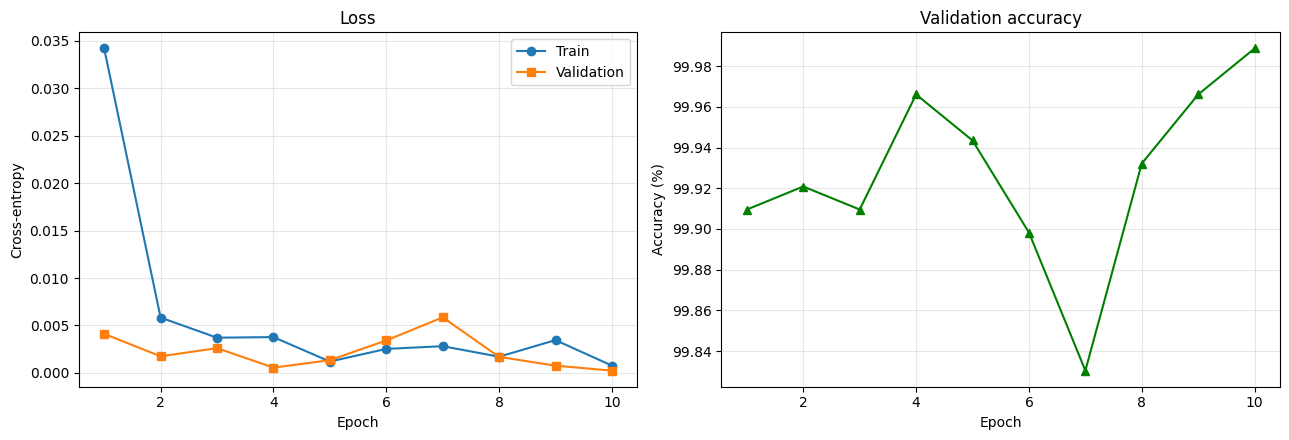

In [19]:
criterion = nn.CrossEntropyLoss()
optimiser = optim.Adam(model.parameters(), lr=1e-3)

history = {"train_loss": [], "val_loss": [], "val_accuracy": []}
EPOCHS = 10

for epoch in range(EPOCHS):
    # --- training ---
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimiser.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimiser.step()
        running_loss += loss.item()

    # --- validation ---
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            val_loss += criterion(outputs, labels).item()
            predicted = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    history["train_loss"].append(running_loss / len(train_loader))
    history["val_loss"].append(val_loss / len(val_loader))
    history["val_accuracy"].append(100 * correct / total)

    print(
        f"Epoch {epoch + 1:2d}/{EPOCHS} | "
        f"train loss {history['train_loss'][-1]:.4f} | "
        f"val loss {history['val_loss'][-1]:.4f} | "
        f"val accuracy {history['val_accuracy'][-1]:.2f}%"
    )

# --- learning curves ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(range(1, EPOCHS + 1), history["train_loss"], marker="o", label="Train")
axes[0].plot(range(1, EPOCHS + 1), history["val_loss"], marker="s", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, EPOCHS + 1), history["val_accuracy"], marker="^", color="green")
axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Reading the curves

We see that the cross-entropy converges after the first epoch.

Validation loss stays close to training loss, so there is no meaningful overfitting.

We could be impressed by the shape of the validation accuracy during epochs 6 and 7.
But this is normal. Firstly, we should pay attention to the scale of the curve; the results are high, always more than 99.82%.
Secondly, this is due to the learning rate: at the convergence point, it is a little too high when the model has converged.
So, it oscillates a little bit.

## 8. Evaluation on the held-out test set

Now that we have the accuracy, we want to know *where* the model is making mistakes. 
In order to answer that question we will analyse each class and make a confusion matrix.

In [20]:
model.eval()
test_predictions = []
test_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        test_predictions.append(outputs.argmax(dim=1).cpu().numpy())
        test_targets.append(labels.numpy())

test_predictions = np.concatenate(test_predictions)
test_targets = np.concatenate(test_targets)
cnn_accuracy = (test_predictions == test_targets).mean() * 100

cnn_errors = int((test_predictions != test_targets).sum())

print(f"{'Model':22s} {'Accuracy':>10s} {'Errors':>8s}")
print("-" * 42)
print(f"{'Logistic regression':22s} {baseline_accuracy:9.2f}% {baseline_errors:8d}")
print(f"{'CNN':22s} {cnn_accuracy:9.2f}% {cnn_errors:8d}")
print(f"\nOut of {len(test_targets):,} test images.")
print(f"Relative error reduction from baseline to CNN: "
      f"{(1 - cnn_errors / baseline_errors) * 100:.1f}%\n")

print(classification_report(test_targets, test_predictions, target_names=class_names, digits=4))

Model                    Accuracy   Errors
------------------------------------------
Logistic regression        99.38%       55
CNN                        99.97%        3

Out of 8,844 test images.
Relative error reduction from baseline to CNN: 94.5%

              precision    recall  f1-score   support

   AbdomenCT     1.0000    1.0000    1.0000      1526
   BreastMRI     0.9992    1.0000    0.9996      1332
         CXR     1.0000    0.9980    0.9990      1475
     ChestCT     1.0000    1.0000    1.0000      1513
        Hand     0.9987    1.0000    0.9993      1496
      HeadCT     1.0000    1.0000    1.0000      1502

    accuracy                         0.9997      8844
   macro avg     0.9997    0.9997    0.9997      8844
weighted avg     0.9997    0.9997    0.9997      8844



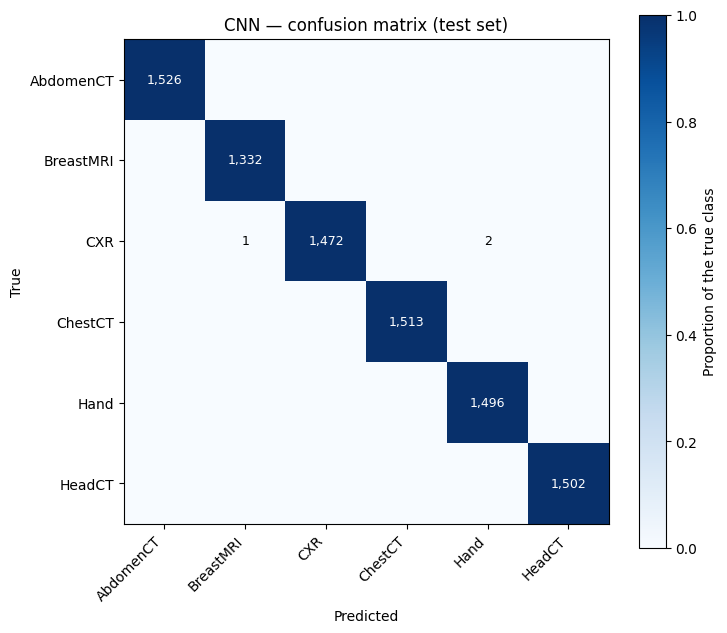

Off-diagonal entries (all confusions):
    1x  CXR          -> predicted BreastMRI
    2x  CXR          -> predicted Hand


In [21]:
def plot_confusion_matrix(targets, predictions, labels, title):
    """Row-normalised confusion matrix, annotated with raw counts."""
    cm = confusion_matrix(targets, predictions)
    cm_normalised = cm / cm.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    image = ax.imshow(cm_normalised, cmap="Blues", vmin=0, vmax=1)

    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)

    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j] == 0:
                continue
            ax.text(
                j, i, f"{cm[i, j]:,}",
                ha="center", va="center",
                color="white" if cm_normalised[i, j] > 0.5 else "black",
                fontsize=9,
            )

    fig.colorbar(image, ax=ax, label="Proportion of the true class")
    plt.tight_layout()
    plt.show()
    return cm


cm = plot_confusion_matrix(
    test_targets, test_predictions, class_names, "CNN — confusion matrix (test set)"
)

print("Off-diagonal entries (all confusions):")
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            print(f"  {cm[i, j]:3d}x  {class_names[i]:12s} -> predicted {class_names[j]}")

3 misclassified test images


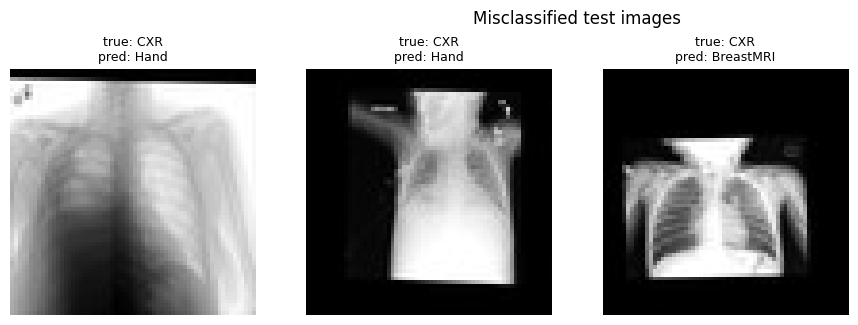

In [22]:
# With so few errors we can afford to look at every single one
error_positions = np.where(test_predictions != test_targets)[0]
print(f"{len(error_positions)} misclassified test images")

if len(error_positions) > 0:
    n_show = min(12, len(error_positions))
    n_cols_err = 4
    n_rows_err = math.ceil(n_show / n_cols_err)
    plt.figure(figsize=(3 * n_cols_err, 3.2 * n_rows_err))

    for k, position in enumerate(error_positions[:n_show]):
        dataset_index = test_idx[position]
        image = Image.open(image_paths[dataset_index]).convert("L")

        plt.subplot(n_rows_err, n_cols_err, k + 1)
        plt.imshow(image, cmap="gray")
        plt.title(
            f"true: {class_names[test_targets[position]]}\n"
            f"pred: {class_names[test_predictions[position]]}",
            fontsize=9,
        )
        plt.axis("off")

    plt.suptitle("Misclassified test images", y=1.0)
    plt.tight_layout()
    plt.show()
else:
    print("No errors to display.")

### Error analysis — the section 2 prediction was wrong

This basic CNN makes 3 errors among 8,844 images. All of them are `CXR` images, two of them were classified as `Hand` and one as `BreastMRI`.
Something interessting is that, at the beging of the notebook, we tought that the three CT classes would be the most difficult to classify. But 
we were wrong, all of them were perfectly classified. 

We need to pay attention, 3 errors are not enough to make a sample. This is noise, a different seed produce a différent set (for exemple 42 missclass 6 pictures, 4 CRX, 1 head and 1 hand). When we look at the pictures wee see that two of them have a bad framing, This may have induce our model into error. But we need to keep in mind that this is a noise.

## 9. Data leakage audit

The score is very high, which raises questions about the independence of the test and training sets. 
This is especially true in medical studies, where a single scan or cross-sectional view from the same 
patient can yield hundreds of slices, generating highly correlated volume in the dataset.

The dataset does not provide us patient identifiers. We need to measure it indirectly. 

In order to do that, we will flatten each image, mean-centre and L2-normalise it, and compute the
cosine similarity between test images and training images of the same class. 
A pair of neighbouring slices from one volume scores near 1.0, two unrelated patients score much
lower. 

After that, we will split the test set into images that do have a
near-duplicate in training and those that do not, and compare accuracy on each part.

In [23]:
def normalised_pixels(indices):
    """Flatten, mean-centre and L2-normalise, so a dot product is a correlation."""
    X = np.stack([
        np.asarray(Image.open(image_paths[i]).convert("L"), dtype=np.float32).ravel()
        for i in indices
    ])
    X -= X.mean(axis=1, keepdims=True)
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)


MAX_TEST_PER_CLASS = 600  # subsampled to keep the audit fast
rng = np.random.default_rng(SEED)

train_idx_array = np.array(train_idx)
test_idx_array = np.array(test_idx)

audit_positions = []   # positions within test_predictions / test_targets
audit_similarity = []  # similarity to the closest training image

print("Cosine similarity to the nearest training image of the same class:\n")
for class_id, class_name in enumerate(class_names):
    test_mask = np.where(image_labels[test_idx_array] == class_id)[0]
    if len(test_mask) > MAX_TEST_PER_CLASS:
        test_mask = rng.choice(test_mask, MAX_TEST_PER_CLASS, replace=False)

    train_same_class = train_idx_array[image_labels[train_idx_array] == class_id]

    X_test_c = normalised_pixels(test_idx_array[test_mask])
    best = np.full(len(test_mask), -1.0, dtype=np.float32)
    # Chunked so the similarity matrix never has to fit in memory at once
    for start in range(0, len(train_same_class), 2000):
        X_train_chunk = normalised_pixels(train_same_class[start:start + 2000])
        best = np.maximum(best, (X_test_c @ X_train_chunk.T).max(axis=1))

    audit_positions.append(test_mask)
    audit_similarity.append(best)
    print(f"  {class_name:12s} median {np.median(best):.4f} | "
          f"above 0.99: {(best > 0.99).mean() * 100:5.1f}% | "
          f"above 0.95: {(best > 0.95).mean() * 100:5.1f}%")

audit_positions = np.concatenate(audit_positions)
audit_similarity = np.concatenate(audit_similarity)

Cosine similarity to the nearest training image of the same class:

  AbdomenCT    median 0.9765 | above 0.99:  13.3% | above 0.95:  72.2%
  BreastMRI    median 0.9827 | above 0.99:  17.0% | above 0.95:  92.5%
  CXR          median 0.8953 | above 0.99:   0.2% | above 0.95:   1.7%
  ChestCT      median 0.7767 | above 0.99:   0.0% | above 0.95:   6.2%
  Hand         median 0.9126 | above 0.99:   0.0% | above 0.95:   3.7%
  HeadCT       median 0.9042 | above 0.99:   1.0% | above 0.95:  15.0%


Does near-duplicate leakage inflate the score?

 threshold   % leaked   acc WITH dup   acc WITHOUT dup
-------------------------------------------------------
      0.99       5.2%       100.000%           99.971%
      0.98      18.0%       100.000%           99.966%
      0.95      31.9%       100.000%           99.959%


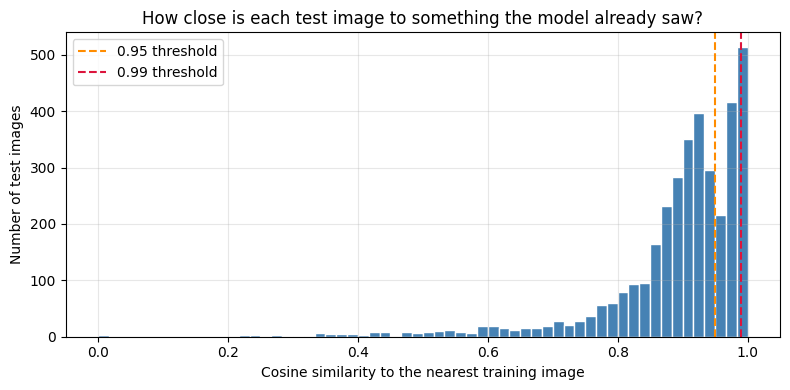

In [24]:
audit_correct = test_predictions[audit_positions] == test_targets[audit_positions]

print("Does near-duplicate leakage inflate the score?\n")
print(f"{'threshold':>10s} {'% leaked':>10s} {'acc WITH dup':>14s} {'acc WITHOUT dup':>17s}")
print("-" * 55)
for threshold in (0.99, 0.98, 0.95):
    duplicated = audit_similarity > threshold
    accuracy_with = audit_correct[duplicated].mean() * 100 if duplicated.any() else float("nan")
    accuracy_without = audit_correct[~duplicated].mean() * 100 if (~duplicated).any() else float("nan")
    print(f"{threshold:>10.2f} {duplicated.mean() * 100:9.1f}% "
          f"{accuracy_with:13.3f}% {accuracy_without:16.3f}%")

plt.figure(figsize=(8, 4))
plt.hist(audit_similarity, bins=60, color="steelblue", edgecolor="white")
plt.axvline(0.95, color="darkorange", linestyle="--", label="0.95 threshold")
plt.axvline(0.99, color="crimson", linestyle="--", label="0.99 threshold")
plt.xlabel("Cosine similarity to the nearest training image")
plt.ylabel("Number of test images")
plt.title("How close is each test image to something the model already saw?")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Results

**Near-duplicates are real and concentrated**. Almost a third of the test images have a training image at cosine similarity above 0.95.
We also see that the effect is very class-dependent. `AbdomenCT` and `BreastMRI` have their median above 0.95. 
The others classes have less than that. This could be explained because abdominal CT and breast MRI series produce
many similar consecutive slices. And chest radiograph is one image per patient. 

**But the leakage does not explain the accuracy.** Because, we have a very high accuracy for each  classes. Even the ones with less cosin similarity.
Futhermore, when we remove the "contaminate" pictures we keep an accuracy above 99.95%.

This is worth being explicit about, because the audit was launched on a hypothesis that
turned out to be **wrong in its consequence**. 

Our first guess was that the accuracy was false because of leakage. We have sown that the leakage has an impact, but it is not significant.
The explantion is just that the task is not very difficult.

But we need to keep in mind that this **method has limitations**. 
Pixel correlation is a proxy for "same patient", not a perfect 
measurement of it.  Two different patients imaged at the same anatomical level can
have a high cosine similarity, and two distant slices from the same patient can have a little one.

## 10. Conclusions




**On the dataset.** This was not a difficult dataset. A simple logistic regression on 256
raw pixels has an accuracy of 99.38%. A small CNN reaches 99.97% ! (this means 3 errors on 8,844 images).
When we inspected the dataset we already found that it was not difficult.
We already see it during the visual inspectation of the pictures, the logistic regression and the very fast 
convergence (after one epoch). We can conclude that the errors are mostly noise. 

**On the model.** The CNN only adds ~0.6%. It is not really important. Something quite fun
is that it remove 94% of the errors (55 to 3).

**On methodology.** We try to go futher than the simple accuracy score. With a leakage analysis 
for example. And that two of our predictions were false. The section
2's confusion prediction and the leakage hypothesis were both refuted by measurement.
